Activity:                      Alishba Nadeem     roll number: 26i-8012

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Load dataset
CATEGORIES = [
    "sci.electronics",
    "rec.autos",
    "comp.sys.mac.hardware",
    "sci.med"
]

print("Loading dataset...")

raw_data = fetch_20newsgroups(
    subset="all",
    categories=CATEGORIES,
    remove=("headers", "footers", "quotes")
)

df = pd.DataFrame({
    "text": raw_data.data,
    "true_label": [raw_data.target_names[i] for i in raw_data.target]
})

# Keep meaningful posts
df = df[df["text"].str.strip().str.len() > 50].reset_index(drop=True)

print(f"Loaded {len(df)} unstructured user posts.")

Loading dataset...
Loaded 3703 unstructured user posts.


Task 1: Text Cleaning, Tokenization & Normalization

In [6]:
# Task 1: Text Cleaning and Normalization

sample_post = df["text"].iloc[0][:400]

print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)

# TODO 1.1: Tokenization and lowercasing
tokens = [
    w.lower()
    for w in word_tokenize(sample_post)
    if w.isalpha()
]

# TODO 1.2: Remove stopwords
stop_words = set(stopwords.words("english"))

filtered_tokens = [
    w for w in tokens
    if w not in stop_words
]

# TODO 1.3: Stemming and Lemmatization
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]

lemmatized_tokens = [
    lemmatizer.lemmatize(w, pos="v")
    for w in filtered_tokens
]

print("Filtered Tokens:  ", filtered_tokens[:12])
print("Stemmed Roots:    ", stemmed_tokens[:12])
print("Lemmatized Words: ", lemmatized_tokens[:12])

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------
Filtered Tokens:   ['honda', 'cable', 'release', 'locked', 'ignition', 'key', 'valet', 'key', 'left', 'someone', 'unlock', 'trunk']
Stemmed Roots:     ['honda', 'cabl', 'releas', 'lock', 'ignit', 'key', 'valet', 'key', 'left', 'someon', 'unlock', 'trunk']
Lemmatized Words:  ['honda', 'cable', 'release', 'lock', 'ignition', 'key', 'valet', 'key', 'leave', 'someone', 'unlock', 'trunk']



Task 2: Bag of Words vs. TF-IDF Feature Extraction

BoW Matrix Shape: (3703, 4000)
TF-IDF Matrix Shape: (3703, 4000)
TF-IDF Sparsity: 99.04%


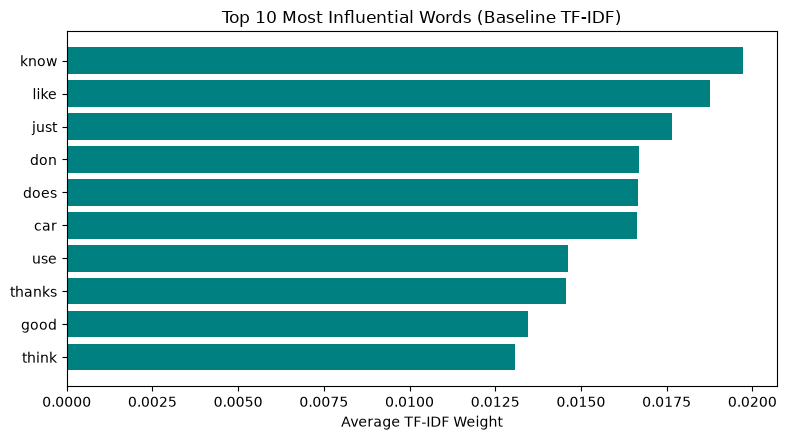

In [8]:

bow_vec = CountVectorizer(
    stop_words="english",
    max_features=4000,
    min_df=5
)

tfidf_vec = TfidfVectorizer(
    stop_words="english",
    max_features=4000,
    min_df=5
)

# TODO 2.2: Fit and transform
X_bow = bow_vec.fit_transform(df["text"])
X_tfidf = tfidf_vec.fit_transform(df["text"])

print("BoW Matrix Shape:", X_bow.shape)
print("TF-IDF Matrix Shape:", X_tfidf.shape)

# TODO 2.3: Calculate sparsity
total_elements = X_tfidf.shape[0] * X_tfidf.shape[1]

sparsity = 100.0 * (1.0 - X_tfidf.nnz / total_elements)

print(f"TF-IDF Sparsity: {sparsity:.2f}%")

# TODO 2.4: Top 10 TF-IDF words
tfidf_means = np.asarray(X_tfidf.mean(axis=0)).ravel()

top_idx = tfidf_means.argsort()[-10:]

top_words = tfidf_vec.get_feature_names_out()[top_idx]
top_scores = tfidf_means[top_idx]

plt.figure(figsize=(8, 4.5))

plt.barh(top_words, top_scores, color="teal")

plt.xlabel("Average TF-IDF Weight")
plt.title("Top 10 Most Influential Words (Baseline TF-IDF)")

plt.tight_layout()
plt.savefig("top_features.png", dpi=150)
plt.show()

Task 3: Automated Topic Discovery

--- Top 8 Words per Cluster ---
Cluster 0: know, like, don, just, does, use, thanks, good
Cluster 1: cadre, dsl, n3jxp, chastity, surrender, intellect, shameful, skepticism
Cluster 2: car, cars, engine, new, just, ford, dealer, like
Cluster 3: mac, apple, drive, monitor, card, thanks, does, know


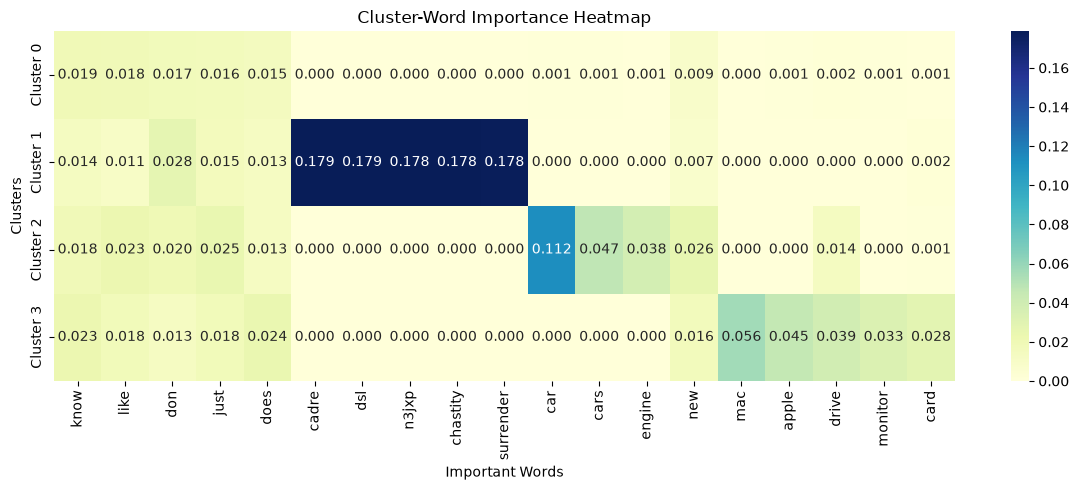

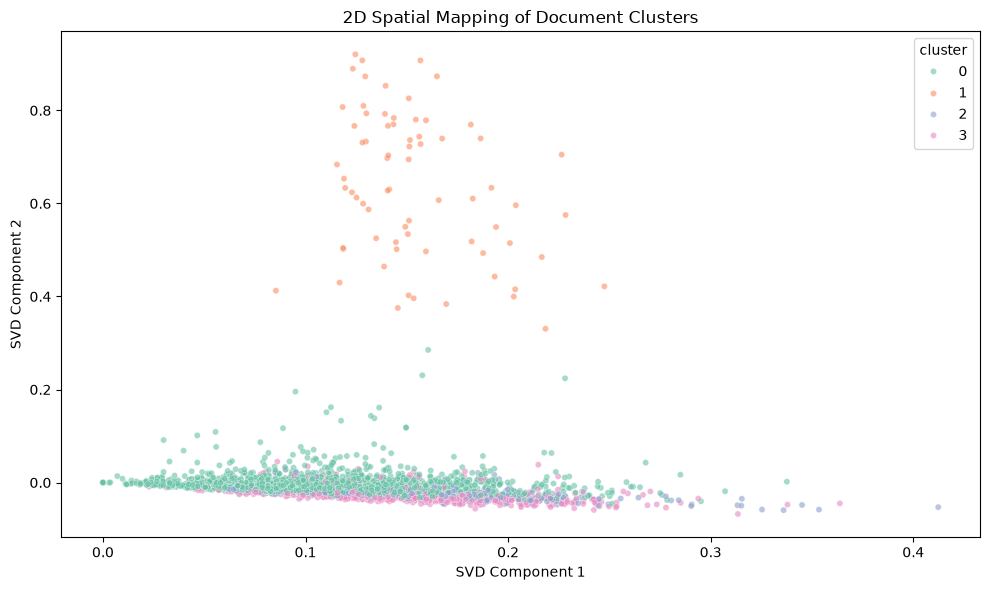

In [9]:
# Task 3: Automated Topic Discovery

# TODO 3.1: Apply K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_tfidf)

# Print top 8 words per cluster
feature_names = tfidf_vec.get_feature_names_out()
centers = kmeans.cluster_centers_

print("--- Top 8 Words per Cluster ---")

for i, center in enumerate(centers):
    top_indices = center.argsort()[-8:][::-1]
    print(f"Cluster {i}:", ", ".join(feature_names[top_indices]))


# TODO 3.2: Cluster importance heatmap

# Collect top 5 features from each cluster
top_indices = []

for center in centers:
    indices = center.argsort()[-5:][::-1]
    top_indices.extend(indices)

# Remove duplicate feature indices
top_indices = list(dict.fromkeys(top_indices))

heatmap_data = pd.DataFrame(
    centers[:, top_indices],
    columns=feature_names[top_indices],
    index=[f"Cluster {i}" for i in range(4)]
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.xlabel("Important Words")
plt.ylabel("Clusters")
plt.title("Cluster-Word Importance Heatmap")

plt.tight_layout()
plt.savefig("cluster_heatmap.png", dpi=150)
plt.show()


# TODO 3.3: Spatial mapping using TruncatedSVD

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_2d = svd.fit_transform(X_tfidf)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_2d[:, 0],
    y=X_2d[:, 1],
    hue=df["cluster"],
    palette="Set2",
    alpha=0.6,
    s=20
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("2D Spatial Mapping of Document Clusters")

plt.tight_layout()
plt.savefig("spatial_mapping.png", dpi=150)
plt.show()

Conversational Filler & Numeric Noise

In [16]:

# Custom conversational stopwords
custom_words = {
    "know", "like", "think", "just",
    "does", "thanks", "use"
}

# Combine with standard English stopwords
all_stopwords = set(stopwords.words("english")).union(custom_words)

# Improved TF-IDF Vectorizer
clean_tfidf_vec = TfidfVectorizer(
    stop_words=list(all_stopwords),
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    max_df=0.5,
    max_features=4000,
    min_df=5
)

X_clean = clean_tfidf_vec.fit_transform(df["text"])

# Refit K-Means
clean_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clean_clusters = clean_kmeans.fit_predict(X_clean)

clean_features = clean_tfidf_vec.get_feature_names_out()

# Compare original vs cleaned cluster words
print("--- Original Cluster Words ---")

for i, center in enumerate(kmeans.cluster_centers_):
    idx = center.argsort()[-8:][::-1]
    print(f"Cluster {i}:", ", ".join(feature_names[idx]))

print("\n--- Cleaned Cluster Words ---")

for i, center in enumerate(clean_kmeans.cluster_centers_):
    idx = center.argsort()[-8:][::-1]
    print(f"Cluster {i}:", ", ".join(clean_features[idx]))

--- Original Cluster Words ---
Cluster 0: know, like, don, just, does, use, thanks, good
Cluster 1: cadre, dsl, n3jxp, chastity, surrender, intellect, shameful, skepticism
Cluster 2: car, cars, engine, new, just, ford, dealer, like
Cluster 3: mac, apple, drive, monitor, card, thanks, does, know

--- Cleaned Cluster Words ---
Cluster 0: geb, pitt, cadre, dsl, chastity, intellect, shameful, surrender
Cluster 1: would, one, anyone, get, also, could, good, much
Cluster 2: car, cars, engine, new, one, would, oil, ford
Cluster 3: mac, apple, drive, monitor, card, would, get, scsi


Challenge 2: Hardware Vocabulary Overlap

In [14]:


print("--- Original Cluster Comparison ---")

original_table = pd.crosstab(
    df["true_label"],
    df["cluster"]
)

print(original_table)

# Inspect common cluster assignments
print("\nElectronics vs Mac Hardware:")

print(original_table.loc[
    ["sci.electronics", "comp.sys.mac.hardware"]
])

# Find cluster with highest combined presence of both categories
hardware_counts = original_table.loc[
    ["sci.electronics", "comp.sys.mac.hardware"]
]

overlap_cluster = hardware_counts.min(axis=0).idxmax()

print("\nCluster with strongest shared hardware presence:", overlap_cluster)

# Show sample posts from both categories in that cluster
for category in ["sci.electronics", "comp.sys.mac.hardware"]:
    samples = df[
        (df["true_label"] == category) &
        (df["cluster"] == overlap_cluster)
    ]["text"].head(2)

    print(f"\n--- {category} ---")
    for post in samples:
        print(post[:400].replace("\n", " "))
        print("-" * 40)

# Apply bigrams
bigram_vec = TfidfVectorizer(
    stop_words="english",
    max_features=4000,
    min_df=5,
    ngram_range=(1, 2)
)

X_bigram = bigram_vec.fit_transform(df["text"])

bigram_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["bigram_cluster"] = bigram_kmeans.fit_predict(X_bigram)

print("\n--- After Adding Bigrams ---")

bigram_table = pd.crosstab(
    df["true_label"],
    df["bigram_cluster"]
)

print(bigram_table)

# Print top words and phrases
bigram_features = bigram_vec.get_feature_names_out()

print("\nTop Features After Bigrams:")

for i, center in enumerate(bigram_kmeans.cluster_centers_):
    idx = center.argsort()[-8:][::-1]
    print(f"Cluster {i}:", ", ".join(bigram_features[idx]))

--- Original Cluster Comparison ---
cluster                  0   1    2    3
true_label                              
comp.sys.mac.hardware  269   0    2  639
rec.autos              396   0  507    2
sci.electronics        860   0   20   60
sci.med                875  71    0    2

Electronics vs Mac Hardware:
cluster                  0  1   2    3
true_label                            
sci.electronics        860  0  20   60
comp.sys.mac.hardware  269  0   2  639

Cluster with strongest shared hardware presence: 0

--- sci.electronics ---
If you want slow LED flash rates, adjustable by switches (or by a 4066/4016 digitally controlled switch), I suggest looking at a 555 oscillator chip. They cost ~$1 at Radio Shack (much cheaper in quantity at quality places), and you will be able to find good info about simple circuits in a 555 oscialltor notebook (I think Forest Mims has one at Radio Shack). You'll have to toy with resistor/capaci
----------------------------------------
Fellow Info-j

In [17]:
# Check technical words shared by both hardware categories

technical_words = [
    "drive", "monitor", "card", "power", "disk",
    "board", "cable", "chip", "port", "memory",
    "hardware", "computer", "device", "controller"
]

for word in technical_words:
    electronics_count = df[
        df["true_label"] == "sci.electronics"
    ]["text"].str.contains(
        rf"\b{word}\b", case=False, regex=True
    ).sum()

    mac_count = df[
        df["true_label"] == "comp.sys.mac.hardware"
    ]["text"].str.contains(
        rf"\b{word}\b", case=False, regex=True
    ).sum()

    if electronics_count > 0 and mac_count > 0:
        print(f"{word}: Electronics={electronics_count}, Mac={mac_count}")

drive: Electronics=38, Mac=140
monitor: Electronics=12, Mac=105
card: Electronics=23, Mac=78
power: Electronics=115, Mac=83
disk: Electronics=25, Mac=76
board: Electronics=46, Mac=73
cable: Electronics=28, Mac=49
chip: Electronics=69, Mac=43
port: Electronics=18, Mac=37
memory: Electronics=23, Mac=74
hardware: Electronics=38, Mac=70
computer: Electronics=53, Mac=87
device: Electronics=45, Mac=23
controller: Electronics=13, Mac=7


3: Rant Length Bias

In [13]:

# Calculate word count per document
word_counts = df["text"].str.split().str.len()

# Identify longest and shortest documents
longest_idx = word_counts.idxmax()
shortest_idx = word_counts.idxmin()

print("Longest Post Words:", word_counts[longest_idx])
print("Shortest Post Words:", word_counts[shortest_idx])

# Compare vector norms
for name, idx in [
    ("Longest Post", longest_idx),
    ("Shortest Post", shortest_idx)
]:
    bow_norm = np.linalg.norm(X_bow[idx].toarray())
    tfidf_norm = np.linalg.norm(X_tfidf[idx].toarray())

    print(f"\n{name}")
    print(f"BoW L2 Norm: {bow_norm:.4f}")
    print(f"TF-IDF L2 Norm: {tfidf_norm:.4f}")

Longest Post Words: 11765
Shortest Post Words: 1

Longest Post
BoW L2 Norm: 276.2408
TF-IDF L2 Norm: 1.0000

Shortest Post
BoW L2 Norm: 0.0000
TF-IDF L2 Norm: 0.0000


In [15]:
def explain_document(doc_id, matrix, vectorizer, top_n=5):

    # Select document
    row = matrix.getrow(doc_id)

    # Get non-zero features and weights
    indices = row.indices
    weights = row.data

    # Find highest-weighted features
    top_positions = np.argsort(weights)[::-1][:top_n]

    feature_names = vectorizer.get_feature_names_out()

    explanation = [
        (feature_names[indices[i]], float(weights[i]))
        for i in top_positions
    ]

    return explanation


# Test Document 412
result = explain_document(
    doc_id=412,
    matrix=X_tfidf,
    vectorizer=tfidf_vec,
    top_n=5
)

print("--- Document 412 Explanation ---")

for word, weight in result:
    print(f"{word}: {weight:.4f}")

print("\nAssigned Cluster:", df.loc[412, "cluster"])
print("True Category:", df.loc[412, "true_label"])

--- Document 412 Explanation ---
discussion: 0.4524
feel: 0.3989
days: 0.3855
need: 0.2885
meant: 0.2667

Assigned Cluster: 0
True Category: rec.autos


In [18]:
import nbformat
from pathlib import Path

notebook = nbformat.read(
    "Lab15_TFIDF_Activity.ipynb",
    as_version=4
)

code = "\n\n".join(
    cell.source
    for cell in notebook.cells
    if cell.cell_type == "code"
    and not cell.source.lstrip().startswith(("%", "!"))
)

Path("lab15_starter.py").write_text(
    code,
    encoding="utf-8"
)

print("lab15_starter.py created successfully!")

lab15_starter.py created successfully!


In [19]:
!python -m pytest test_lab15.py -v

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Computer House\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Computer House\Downloads\textanalysis_tfidf-main\textanalysis_tfidf-main
plugins: anyio-4.12.1
collecting ... collected 6 items

test_lab15.py::test_starter_file_exists PASSED                           [ 16%]
test_lab15.py::test_dataset_loading PASSED                               [ 33%]
test_lab15.py::test_step1_tokenization PASSED                            [ 50%]
test_lab15.py::test_step2_vectorization PASSED                           [ 66%]
test_lab15.py::test_step3_clustering PASSED                              [ 83%]
test_lab15.py::test_challenge_functions PASSED                           [100%]

============================= 6 passed in 35.00s ==============================
